# Unit 3: Menelaah Data
**Kode unit:** J.62DMI00.005.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** mengenal isi data: ukuran, tipe, pola, dan hubungan antarvariabel.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

## 1. Membaca data

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])
print('Jumlah baris :', len(df))
print('Jumlah kolom :', df.shape[1])
print('Periode      :', df['Date'].min().date(), 's.d.', df['Date'].max().date())
df.head()

Jumlah baris : 4365
Jumlah kolom : 7
Periode      : 2010-01-01 s.d. 2026-09-30


,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX
0,2010-01-01,NaN,NaN,9385.599609,NaN,NaN,NaN
1,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001
2,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000
3,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000
4,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999


### Keterangan setiap variabel

| Kolom | Nama lengkap | Apa itu? | Satuan | Kode Yahoo Finance |
|---|---|---|---|---|
| Date | Tanggal | Hari kerja Senin–Jumat | – | – |
| IHSG | Indeks Harga Saham Gabungan | Indeks yang merangkum pergerakan harga **seluruh saham di Bursa Efek Indonesia (BEI)** | poin indeks (nilai dasar 100 pada 10 Agustus 1982) | ^JKSE |
| SP500 | Standard & Poor's 500 | Indeks **500 perusahaan terbesar di Amerika Serikat** (mis. Apple, Microsoft, Nvidia) yang tercatat di bursa NYSE dan Nasdaq; cerminan utama pasar saham AS | poin indeks | ^GSPC |
| VIX | Cboe Volatility Index | "Indeks ketakutan": perkiraan investor tentang **besarnya gejolak pasar saham AS dalam 30 hari ke depan**, dihitung oleh bursa Cboe dari harga opsi S&P 500 | poin (% gejolak per tahun) | ^VIX |
| OIL | Minyak mentah WTI | Harga kontrak berjangka minyak mentah *West Texas Intermediate* di bursa NYMEX (AS), salah satu acuan harga minyak dunia | USD per barel (≈ 159 liter) | CL=F |
| GOLD | Emas | Harga kontrak berjangka emas di bursa COMEX (AS) | USD per troy ounce (≈ 31,1 gram) | GC=F |
| USDIDR | Kurs dolar AS terhadap rupiah | Banyaknya **rupiah untuk membeli 1 dolar AS**; angka naik berarti rupiah **melemah** | rupiah per 1 USD | IDR=X |

### Cara membaca dan kaitannya dengan IHSG

- **IHSG** — jika IHSG naik, rata-rata harga saham di BEI (ditimbang menurut besar perusahaan) naik. BEI berdagang
  Senin–Jumat sekitar pukul **09.00–16.00 WIB**. Di proyek ini IHSG menjadi **sumber target** (naik/turun besok)
  sekaligus fitur.
- **S&P 500** — bursa AS berdagang pukul 09.30–16.00 waktu New York, atau sekitar **20.30–03.00 WIB** (Maret–November)
  dan **21.30–04.00 WIB** (November–Maret). Karena bursa AS buka setelah BEI tutup, hasilnya menjadi informasi baru
  bagi IHSG keesokan harinya.
- **VIX** — di bawah ±20 berarti pasar relatif tenang (71% hari dalam data ini), di atas ±30 berarti investor cemas
  (6% hari). Nilai tertinggi dalam data adalah **82,69 pada 16 Maret 2020** (awal pandemi COVID-19). Saat VIX naik,
  investor global cenderung menjual aset berisiko, termasuk saham di negara berkembang seperti Indonesia.
- **Minyak (OIL)** — banyak perusahaan energi dan tambang tercatat di BEI, dan harga minyak juga mencerminkan perkiraan
  pertumbuhan ekonomi dunia. Harga ini pernah **negatif (−37,63) pada 20 April 2020** karena kontrak Mei 2020 hampir
  jatuh tempo saat tempat penyimpanan minyak di AS hampir penuh.
- **Emas (GOLD)** — dianggap aset aman (*safe haven*) yang dicari saat pasar bergejolak; pergerakannya mencerminkan
  sentimen global dan memengaruhi saham tambang logam.
- **Kurs (USDIDR)** — rupiah yang melemah (angka naik) sering terjadi bersamaan dengan investor asing menjual saham dan
  obligasi Indonesia. Data harian kurs di Yahoo Finance ditutup pada tengah malam waktu London (sekitar pukul
  06.00–07.00 WIB), sehingga sudah tersedia sebelum BEI dibuka. Rupiah terlemah dalam data adalah **18.190 per dolar
  pada 9 Juni 2026**.

### Istilah penting
- **Indeks saham:** satu angka yang merangkum pergerakan harga sekumpulan saham.
- **Kontrak berjangka (*futures*):** perjanjian jual-beli suatu barang pada harga tertentu untuk waktu yang akan datang;
  harganya dipakai sebagai acuan harga pasar harian.
- **Harga penutupan:** harga terakhir pada satu hari perdagangan. Data ini memakai harga penutupan.
- **Volatilitas:** besarnya naik-turun harga.

**Sumber data:** Yahoo Finance, harga penutupan harian, diperbarui sampai 30 September 2026. Pada hari libur suatu
pasar, nilainya diisi dengan nilai hari sebelumnya.

## 2. Tipe data dan statistik ringkas

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4365 non-null   datetime64[ns]
 1   OIL     4364 non-null   float64       
 2   GOLD    4364 non-null   float64       
 3   USDIDR  4365 non-null   float64       
 4   SP500   4364 non-null   float64       
 5   IHSG    4364 non-null   float64       
 6   VIX     4364 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 238.8 KB


In [4]:
df.describe().round(2)

,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX
count,4365,4364.00,4364.00,4365.00,4364.00,4364.00,4364.00
mean,2018-05-14 23:48:07.422680320,72.08,1791.03,13245.93,3135.73,5593.20,18.38
min,2010-01-01 00:00:00,-37.63,1050.80,888.11,1022.58,2475.48,9.14
25%,2014-03-10 00:00:00,55.70,1273.48,11601.00,1848.38,4585.21,13.84
50%,2018-05-15 00:00:00,72.08,1561.25,13886.94,2681.56,5783.32,16.70
75%,2022-07-20 00:00:00,88.91,1874.62,14935.00,4224.32,6641.98,20.94
max,2026-09-30 00:00:00,123.70,5318.40,18190.30,7798.99,9134.70,82.69
std,NaN,20.71,827.79,2542.86,1706.70,1321.53,6.73


Nilai terendah dan tertinggi setiap variabel beserta tanggalnya:

In [5]:
ringkas = []
for k in ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR']:
    s = df.set_index('Date')[k].dropna()
    ringkas.append({'Variabel': k,
                    'Terendah': round(s.min(), 2), 'Tanggal terendah': s.idxmin().date(),
                    'Tertinggi': round(s.max(), 2), 'Tanggal tertinggi': s.idxmax().date(),
                    'Terakhir (30 Sep 2026)': round(s.iloc[-1], 2)})
pd.DataFrame(ringkas)

,Variabel,Terendah,Tanggal terendah,Tertinggi,Tanggal tertinggi,Terakhir (30 Sep 2026)
0,IHSG,2475.48,2010-02-08,9134.70,2026-01-20,6071.14
1,SP500,1022.58,2010-07-02,7798.99,2026-08-13,7651.54
2,VIX,9.14,2017-11-03,82.69,2020-03-16,16.34
3,OIL,-37.63,2020-04-20,123.70,2022-03-08,90.42
4,GOLD,1050.80,2015-12-17,5318.40,2026-01-29,4186.70
5,USDIDR,888.11,2010-11-01,18190.30,2026-06-09,17736.40


Nilai terendah USDIDR (**888 pada 1 November 2010**) jelas salah catat; kurs saat itu sekitar 8.900 per dolar. Data
seperti ini diperiksa di Unit 4.

## 3. Grafik setiap variabel

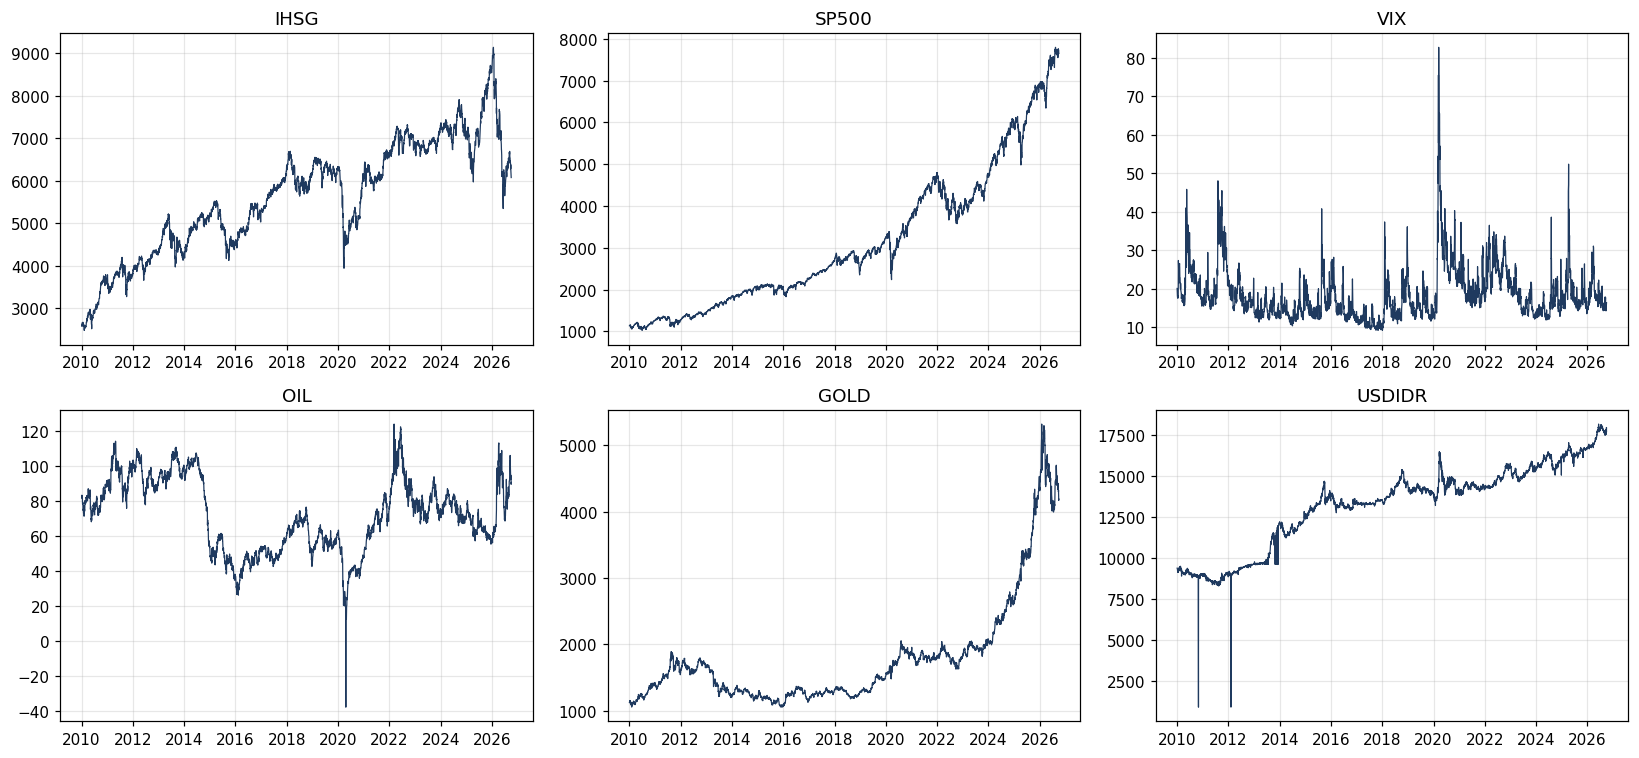

In [6]:
kolom = ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, k in zip(axes.flat, kolom):
    ax.plot(df['Date'], df[k], linewidth=0.8, color='#1f3a5f')
    ax.set_title(k)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/03_grafik_variabel.png', dpi=150, bbox_inches='tight')
plt.show()

Terlihat dua hal yang perlu diperiksa di Unit 4: harga minyak (OIL) sempat **negatif** pada 2020, dan grafik USDIDR
memiliki beberapa **lonjakan tajam ke bawah** yang tidak wajar.

## 4. Seberapa sering IHSG naik?

In [7]:
ihsg = df[['Date', 'IHSG']].dropna()
perubahan = ihsg['IHSG'].pct_change() * 100
perubahan = perubahan[perubahan != 0].dropna()   # abaikan hari libur BEI (nilai tidak berubah)
print(f'Hari IHSG naik  : {(perubahan > 0).mean():.1%}')
print(f'Hari IHSG turun : {(perubahan < 0).mean():.1%}')

Hari IHSG naik  : 54.0%
Hari IHSG turun : 46.0%


## 5. Variabel mana yang berhubungan dengan arah IHSG besok?
Kita hitung korelasi antara perubahan setiap variabel **hari ini** dengan perubahan IHSG **besok**. Agar adil, analisis
ini hanya memakai data 2010–2022, sebelum periode data uji dimulai (28 April 2023). Korelasi Spearman dipakai karena tidak
mudah terpengaruh nilai ekstrem.

VIX      -0.236
USDIDR   -0.018
IHSG      0.002
GOLD      0.086
OIL       0.137
SP500     0.289
Name: IHSG_besok, dtype: float64


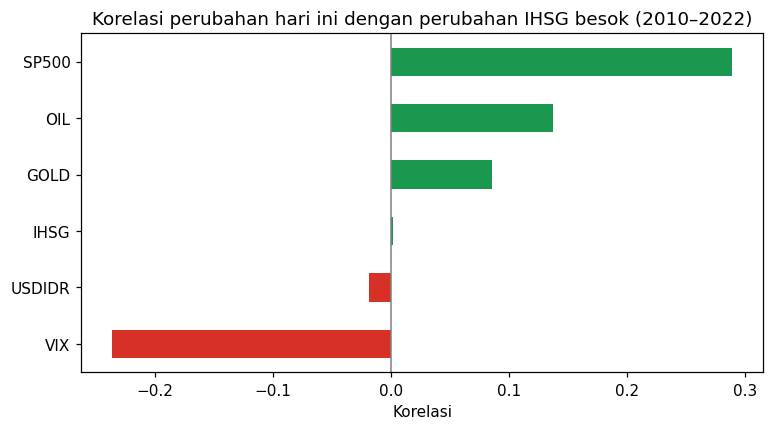

In [8]:
data = df[df['Date'] <= '2022-12-31'].dropna()
data = data[data['IHSG'].diff() != 0]            # hanya hari bursa BEI
chg = data[kolom].pct_change() * 100
chg['IHSG_besok'] = chg['IHSG'].shift(-1)
korelasi = chg.corr(method='spearman')['IHSG_besok'].drop('IHSG_besok').sort_values()
print(korelasi.round(3))

warna = ['#1a9850' if v > 0 else '#d73027' for v in korelasi]
korelasi.plot(kind='barh', color=warna, figsize=(8, 4))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Korelasi perubahan hari ini dengan perubahan IHSG besok (2010–2022)')
plt.xlabel('Korelasi')
plt.savefig('../figures/03_korelasi_ihsg_besok.png', dpi=150, bbox_inches='tight')
plt.show()

## Kesimpulan
- Data berisi **4.365 hari kerja** (1 Jan 2010 – 30 Sep 2026) dengan 6 variabel pasar.
- IHSG naik pada sekitar **54%** hari bursa, jadi kelas Naik dan Turun cukup seimbang.
- **S&P 500** paling berhubungan dengan arah IHSG besok (korelasi +0,29): jika bursa Amerika naik semalam, IHSG
  cenderung naik keesokan harinya. **VIX** berhubungan terbalik (−0,24).
- **Kurs USD/IDR** hampir tidak berhubungan dengan arah IHSG besok (korelasi −0,02).
- Ada data yang janggal (harga minyak negatif dan lonjakan kurs) yang diperiksa di Unit 4.